# 02 · Modelagem do Klike Score

**Perguntas do desafio**
1. Feature engineering: quais features e por quê? Alguma feature nova?
2. Modelo: treinar ao menos um modelo de regressão e justificar a escolha.
3. Avaliação: métricas apropriadas e interpretação.
4. Feature importance: o que mais influencia o score? Faz sentido para o negócio?

**Diferencial:** além de prever, faço a **engenharia reversa do score**, isto é, quantos pontos vale cada atributo do criativo em cada plataforma. É essa tabela que alimenta a engine de recomendações da Parte 3.

Código reutilizável em `src/klike/features.py` e `src/klike/model.py`. Conceitos (validação cruzada, RMSE, vazamento etc.) em `docs/conceitos.md`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold, cross_val_predict

from klike.data import load_clean, TARGET, PLATFORMS
from klike.features import build_features, LEVELS
from klike.model import cross_validate_models, make_linear, coefficients, CV
from klike.paths import FIGURES_MODEL

pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

df = load_clean()
y = df[TARGET]

## 1. Decisão central: o que o modelo pode "ver"?

O dataset mistura dois tipos de informação:
- **antes de veicular**, que o anunciante conhece e controla: atributos do criativo (hook, rosto, formato…) e contexto (plataforma, objetivo, público);
- **depois de veicular**, que só existe com a campanha no ar: CTR, engajamento, retenção, conversão, ROAS.

O Klike pontua criativos para **apoiar decisões antes de investir**. Um modelo que usa CTR para prever o score não serve para isso: no momento da decisão, o CTR ainda não existe. Usar essa informação seria **vazamento de dados** (*data leakage*). Por isso treino dois modelos:

| Modelo | Features | Para que serve |
|---|---|---|
| **A · Pré-lançamento** | criativo + contexto | **modelo principal**, usado pela engine de recomendações |
| **B · Completo** | A + métricas de performance | diagnóstico: quanto do score a performance observada explica? |

## 2. Feature engineering

| Grupo | Features | Por quê |
|---|---|---|
| Criativo (sim/não) | `hook`, `face`, `cta`, `subtitle` | as alavancas mais fortes da EDA |
| Criativo (categórico) | `format`, `text_density` (one-hot) | a EDA mostrou efeito **não monotônico** do texto ("medium" > "low" e "high"); one-hot captura isso, um número ordinal não captaria |
| Criativo (contínuo) | `music_voice_ratio`, `log_duration` | duração em **log**: passar de 10s para 20s pesa o mesmo que de 30s para 60s |
| Contexto | `platform`, `category`, `objective`, `target_audience_age`, `retargeting` | controlam o mix de campanhas (lição do confounding na EDA) |
| **Interações com a plataforma** (novas) | `plataforma × formato`, `× texto`, `× hook`, `× rosto`, `× legenda` | a EDA mostrou que o efeito desses atributos **muda por plataforma** (ex.: vertical é ótimo no TikTok e ruim no LinkedIn) |
| Faltantes (nova) | `subtitle_missing` | legenda faltante vira "sem legenda" + flag, em vez de imputar pela mediana (que seria "com legenda") |
| Performance (só modelo B) | `ctr`, `engagement_rate`, `watch_ratio` (nova), `conversion_rate` (nova), `log_roas` | taxas, não volumes: volume reflete orçamento, não qualidade |

**Testadas e descartadas** (não melhoraram a validação cruzada):
- **desvio da duração em relação à mediana da plataforma**, para captar uma "duração ideal";
- **rosto × público jovem**, que aparece no engajamento mas não no score.

Menos features significa menos risco de overfitting com 500 linhas.

In [2]:
XA = build_features(df)
XB = build_features(df, include_performance=True)
print(f"Modelo A: {XA.shape[1]} features · Modelo B: {XB.shape[1]} features")
XA.head(3).T.head(12)

Modelo A: 38 features · Modelo B: 43 features


,0,1,2
hook,0.00,1.00,1.000000
face,1.00,1.00,1.000000
cta,1.00,1.00,1.000000
subtitle,1.00,1.00,1.000000
subtitle_missing,0.00,0.00,0.000000
music_voice_ratio,0.39,0.07,0.430000
log_duration,NaN,NaN,2.079442
retargeting,0.00,0.00,0.000000
format=quadrado,0.00,0.00,0.000000
format=horizontal,0.00,1.00,0.000000


## 3. Comparação de modelos

**Protocolo:** validação cruzada **5-fold repetida 3 vezes** (15 rodadas de treino e teste). Com 500 linhas, um único corte treino/teste seria muito sensível à sorte de quais campanhas caem no teste; repetir dá uma estimativa estável e um desvio-padrão.

**Candidatos**
- **Baseline:** prever sempre a média. Um modelo só tem valor se superar isso.
- **Linear (Ridge):** simples, interpretável e com regularização leve contra overfitting.
- **Gradient Boosting:** captura não linearidades e interações automaticamente.

In [3]:
cv_results = cross_validate_models(df)
cv_results.round(3)

,RMSE,RMSE (dp),MAE,MAE (dp),R2,R2 (dp)
modelo,,,,,,
Baseline (média),15.571,0.908,12.584,0.834,-0.008,0.009
A · Linear,8.308,0.622,6.630,0.420,0.708,0.059
A · Gradient Boosting,9.540,0.690,7.641,0.565,0.618,0.055
B · Linear,6.576,0.484,5.301,0.357,0.818,0.035
B · Gradient Boosting,6.813,0.469,5.471,0.414,0.805,0.031


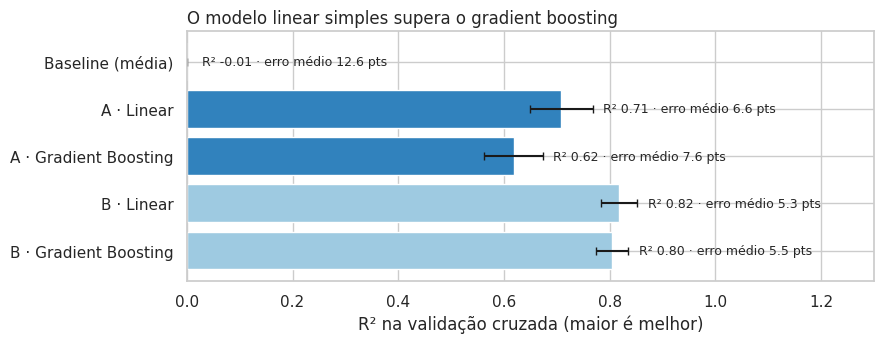

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
order = cv_results.index[::-1]
colors = ["#bdbdbd" if "Baseline" in m else ("#3182bd" if m.startswith("A") else "#9ecae1") for m in order]
ax.barh(order, cv_results.loc[order, "R2"], xerr=cv_results.loc[order, "R2 (dp)"], color=colors, capsize=3)
for i, m in enumerate(order):
    ax.text(max(cv_results.loc[m, "R2"], 0) + cv_results.loc[m, "R2 (dp)"] + .02, i, f"R² {cv_results.loc[m, 'R2']:.2f} · erro médio {cv_results.loc[m, 'MAE']:.1f} pts", va="center", fontsize=9)
ax.set(xlim=(0, 1.3), xlabel="R² na validação cruzada (maior é melhor)")
ax.set_title("O modelo linear simples supera o gradient boosting", loc="left", fontsize=12)
plt.tight_layout()
fig.savefig(FIGURES_MODEL / "01_comparacao_modelos.png", dpi=150, bbox_inches="tight")

**📊 Como ler:** cada barra é o R² médio do modelo nas 15 rodadas de validação cruzada; a linha preta é a variação entre rodadas (± 1 desvio-padrão). Ao lado, o erro absoluto médio em pontos de score.

**O que o gráfico mostra**
- O **baseline** tem R² ≈ 0 e erra em média 12,6 pontos, que é o ponto de partida.
- O **modelo A linear** explica **~71%** da variação do score, com erro médio de **~6,6 pontos** numa escala de 0 a 100.
- O **gradient boosting** é **pior** que o linear no modelo A (R² 0,62), e só empata no modelo B.
- Adicionar as métricas de performance (modelo B) sobe o R² para **~0,82** e reduz o erro para ~5,3 pontos.

**💡 Takeaway:** com só os atributos do criativo e o contexto, já dá para prever o score com erro de ~6–7 pontos. O modelo mais simples ganha, o que é um forte indício de que **o score é construído de forma aditiva**: cada atributo soma ou subtrai pontos, sem interações complexas que justifiquem árvores.

### 3.1 Escolha do modelo: A · Linear

- **Melhor desempenho** entre os modelos que podem ser usados antes da veiculação.
- **Interpretável:** cada coeficiente é "quantos pontos de score o atributo vale". Isso responde diretamente à pergunta de feature importance e vira a base quantitativa das recomendações.
- **Estável com poucos dados:** 500 linhas e 38 features; a regularização do Ridge evita coeficientes exagerados.
- **Coerente com o fenômeno:** a EDA já mostrava uma "escada" quase linear de boas práticas (36 → 81).

O gradient boosting fica como referência: se ele fosse muito melhor, seria sinal de não linearidades que o linear não captura. Não é o caso.

## 4. Avaliação detalhada do modelo A

As previsões abaixo são **out-of-fold**: cada campanha é prevista por um modelo que **não a viu no treino**, simulando o uso em campanhas novas.

,n,erro_medio_abs,vies
platform,,,
LinkedIn,83.0,7.06,-0.16
Meta,241.0,6.18,-0.03
TikTok,176.0,7.05,0.09
Total,500.0,6.63,-0.01


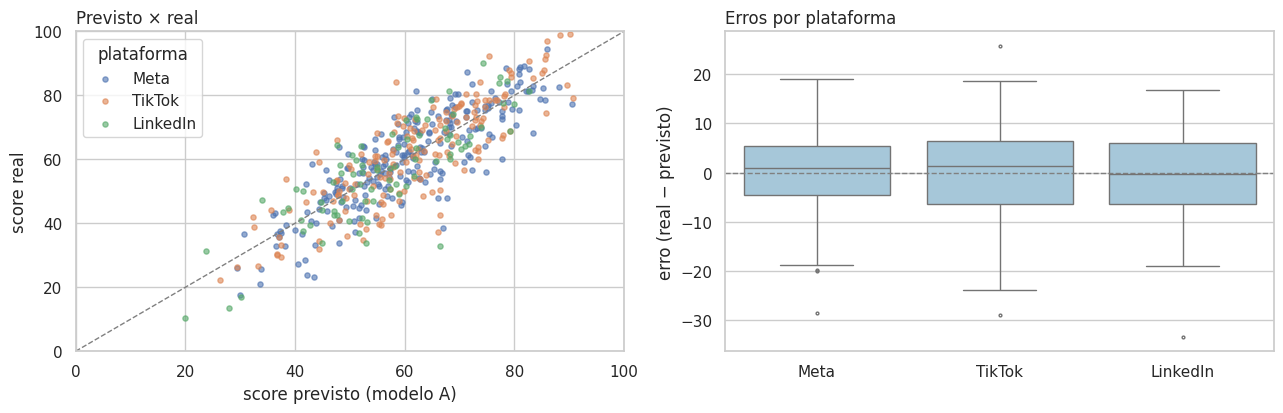

In [5]:
oof = cross_val_predict(make_linear(), XA, y, cv=KFold(5, shuffle=True, random_state=42))
res = y - oof

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
for p in PLATFORMS:
    m = df["platform"] == p
    ax.scatter(oof[m], y[m], s=14, alpha=.6, label=p)
ax.plot([0, 100], [0, 100], color="gray", ls="--", lw=1)
ax.set(xlabel="score previsto (modelo A)", ylabel="score real", xlim=(0, 100), ylim=(0, 100))
ax.legend(title="plataforma")
ax.set_title("Previsto × real", loc="left")

ax = axes[1]
sns.boxplot(x=df["platform"], y=res, order=PLATFORMS, color="#9ecae1", ax=ax, fliersize=2)
ax.axhline(0, color="gray", ls="--", lw=1)
ax.set(xlabel="", ylabel="erro (real − previsto)")
ax.set_title("Erros por plataforma", loc="left")
plt.tight_layout()
fig.savefig(FIGURES_MODEL / "02_previsto_vs_real.png", dpi=150, bbox_inches="tight")

err = pd.DataFrame({"platform": df["platform"], "abs_err": res.abs(), "res": res})
summary = err.groupby("platform").agg(n=("res", "size"), erro_medio_abs=("abs_err", "mean"), vies=("res", "mean"))
summary.loc["Total"] = [len(err), err["abs_err"].mean(), err["res"].mean()]
summary.round(2)

In [6]:
# O modelo acerta mais nos extremos ou no meio? E qual fração das campanhas erra por mais de 10 pts?
bins = pd.cut(y, [0, 40, 55, 70, 85, 100])
display(pd.DataFrame({"erro médio abs.": res.abs().groupby(bins, observed=True).mean(),
                      "viés (real − previsto)": res.groupby(bins, observed=True).mean(),
                      "n": res.groupby(bins, observed=True).size()}).round(2))
print(f"Campanhas com erro > 10 pts: {(res.abs() > 10).mean():.0%}")

,erro médio abs.,viés (real − previsto),n
klike_score,,,
"(0, 40]",10.14,-9.32,51
"(40, 55]",6.17,-3.04,130
"(55, 70]",5.91,0.91,180
"(70, 85]",6.39,4.43,116
"(85, 100]",8.24,8.24,23


Campanhas com erro > 10 pts: 24%


**📊 Como ler**
- **Esquerda:** cada ponto é uma campanha. Se a previsão fosse perfeita, todos os pontos cairiam na linha tracejada.
- **Direita:** distribuição do erro (real − previsto) por plataforma. Uma caixa centrada em zero indica que o modelo não superestima nem subestima sistematicamente aquela plataforma.

**O que os resultados mostram**
- Os pontos acompanham bem a diagonal, com dispersão de ~±8 pontos.
- Os erros são **centrados em zero nas três plataformas**: o modelo não favorece nenhuma, inclusive o LinkedIn, que tem menos dados.
- Há uma **regressão à média**: o modelo superestima campanhas muito ruins e subestima as excelentes. É o comportamento típico de um modelo regularizado. Para recomendações isso é bom, porque as estimativas de ganho ficam conservadoras.

**💡 Takeaway:** o modelo é confiável para **ordenar e comparar** criativos e para estimar o **efeito de mudanças**. Não é confiável para cravar o score exato de uma campanha individual: **uma em cada quatro (24%)** erra por mais de 10 pontos, principalmente nos extremos.

## 5. Feature importance

**Permutation importance:** embaralho uma coluna original do dataset (ex.: `has_hook`), refaço todas as features que dependem dela, inclusive as interações, e meço o quanto o erro do modelo piora. Se piorar muito, o modelo depende muito daquela informação. Agrupar por coluna original evita espalhar a importância do formato entre várias dummies.

,aumento do RMSE,dp
Hook,6.63,0.27
Rosto,3.67,0.20
Densidade de texto,3.18,0.17
Legenda,1.90,0.17
CTA,1.65,0.15
Plataforma,1.08,0.12
Formato,0.59,0.08
Retargeting,0.42,0.08
Categoria,0.31,0.08
Objetivo,0.13,0.03


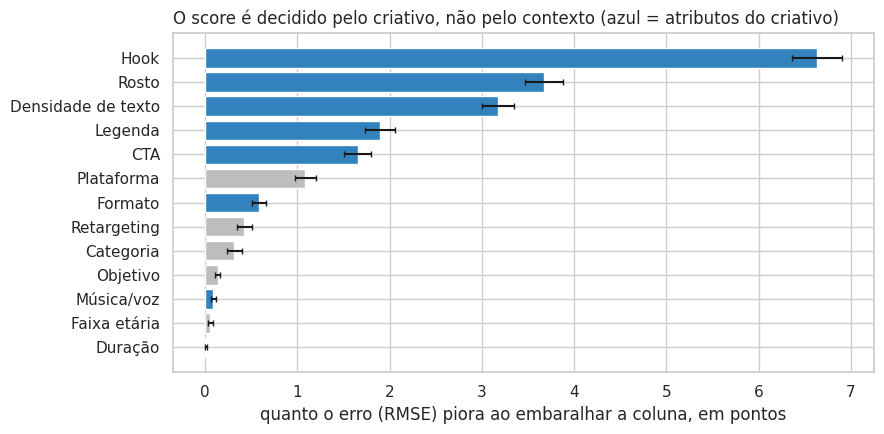

In [7]:
model_A = make_linear().fit(XA, y)
rmse_base = np.sqrt(np.mean((y - model_A.predict(XA)) ** 2))
rng = np.random.default_rng(42)
raw_cols = {
    "has_hook": "Hook", "has_face": "Rosto", "has_cta": "CTA", "has_subtitle": "Legenda",
    "text_density": "Densidade de texto", "format": "Formato", "music_voice_ratio": "Música/voz",
    "video_duration_s": "Duração", "platform": "Plataforma", "category": "Categoria",
    "objective": "Objetivo", "target_audience_age": "Faixa etária", "is_retargeting": "Retargeting",
}
imp = {}
for col, label in raw_cols.items():
    deltas = []
    for _ in range(20):
        d = df.copy()
        d[col] = rng.permutation(d[col].to_numpy())
        pred = model_A.predict(build_features(d))
        deltas.append(np.sqrt(np.mean((y - pred) ** 2)) - rmse_base)
    imp[label] = (np.mean(deltas), np.std(deltas))
imp = pd.DataFrame(imp, index=["aumento do RMSE", "dp"]).T.sort_values("aumento do RMSE")

creative_set = {"Hook", "Rosto", "CTA", "Legenda", "Densidade de texto", "Formato", "Música/voz", "Duração"}
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(imp.index, imp["aumento do RMSE"], xerr=imp["dp"],
        color=["#3182bd" if i in creative_set else "#bdbdbd" for i in imp.index], capsize=2)
ax.set(xlabel="quanto o erro (RMSE) piora ao embaralhar a coluna, em pontos")
ax.set_title("O score é decidido pelo criativo, não pelo contexto (azul = atributos do criativo)", loc="left", fontsize=12)
plt.tight_layout()
fig.savefig(FIGURES_MODEL / "03_importancia_features.png", dpi=150, bbox_inches="tight")
imp.round(2)[::-1]

**📊 Como ler:** cada barra mostra quantos pontos o erro do modelo aumenta quando aquela informação é embaralhada (destruída). Azul são atributos do criativo; cinza, contexto da campanha.

**O que o gráfico mostra**
- **Hook** é, de longe, a informação mais importante: embaralhá-lo piora o erro em 6,6 pontos. Depois vêm **rosto** (3,7), **densidade de texto** (3,2) e, empatados, **legenda** e **CTA** (~1,7–1,9).
- O **contexto** (plataforma, categoria, objetivo, idade) tem importância pequena isoladamente. A plataforma importa principalmente **por meio das interações** (o mesmo formato vale diferente em cada uma).
- **Duração** e **proporção música/voz** quase não importam.

**💡 Faz sentido para o negócio?** Sim:
- O Klike Score se propõe a medir a **qualidade do criativo**, e é exatamente o criativo que o determina. Um score dominado pela categoria ou pelo objetivo seria um problema: diria mais sobre o anunciante do que sobre o vídeo.
- A ordem bate com as boas práticas de mercado para vídeo em feed: prender a atenção nos primeiros segundos (hook) e humanizar (rosto) vêm antes de detalhes de produção.
- A duração pouco relevante é coerente com a EDA (D10). O que importa é prender a atenção no início, mais do que o tamanho do vídeo.

## 6. Engenharia reversa do score: quanto vale cada atributo?

Como o modelo é linear e as features estão em unidades naturais (0/1), cada coeficiente é **diretamente** "quantos pontos de score o atributo soma, mantendo tudo o mais constante". Combinando o coeficiente base com o da interação, obtenho o valor **por plataforma**.

In [8]:
coef = coefficients(model_A, list(XA.columns))

def platform_value(feature):
    out = {}
    for p in PLATFORMS:
        inter = f"{p}×{feature}"
        out[p] = coef[feature] + (coef[inter] if inter in coef else 0.0)
    return out

rows = {
    "Adicionar hook": platform_value("hook"),
    "Adicionar rosto humano": platform_value("face"),
    "Adicionar CTA": platform_value("cta"),
    "Adicionar legenda": platform_value("subtitle"),
    "Texto: low → medium": platform_value("text_density=medium"),
    "Texto: low → high": platform_value("text_density=high"),
    "Formato: vertical → quadrado": platform_value("format=quadrado"),
    "Formato: vertical → horizontal": platform_value("format=horizontal"),
}
points = pd.DataFrame(rows).T[PLATFORMS]
points.loc["Formato: vertical → horizontal", "TikTok"] = np.nan  # sem campanhas horizontais no TikTok
points.loc["Música/voz: 0 → 1 (só voz → só música)"] = coef["music_voice_ratio"]
points.loc["Duração: dobrar o vídeo"] = coef["log_duration"] * np.log(2)
points.round(1)

,Meta,TikTok,LinkedIn
Adicionar hook,16.1,16.9,19.4
Adicionar rosto humano,11.2,12.4,11.6
Adicionar CTA,8.0,8.0,8.0
Adicionar legenda,7.3,10.5,4.4
Texto: low → medium,7.4,5.2,8.7
Texto: low → high,-7.4,-7.7,-7.7
Formato: vertical → quadrado,0.8,-3.2,0.2
Formato: vertical → horizontal,-4.1,NaN,4.7
Música/voz: 0 → 1 (só voz → só música),-4.1,-4.1,-4.1
Duração: dobrar o vídeo,-0.3,-0.3,-0.3


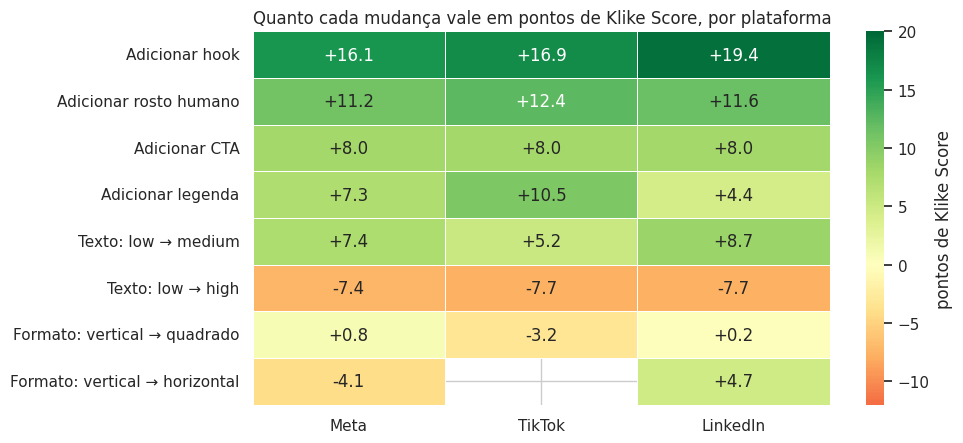

In [9]:
plot = points.drop(index=["Música/voz: 0 → 1 (só voz → só música)", "Duração: dobrar o vídeo"])
fig, ax = plt.subplots(figsize=(10, 4.6))
sns.heatmap(plot, annot=plot.map(lambda v: "" if pd.isna(v) else f"{v:+.1f}"), fmt="", cmap="RdYlGn", center=0,
            vmin=-12, vmax=20, linewidths=.5, cbar_kws={"label": "pontos de Klike Score"}, ax=ax)
ax.set(xlabel="", ylabel="")
ax.tick_params(axis="y", rotation=0)
ax.set_title("Quanto cada mudança vale em pontos de Klike Score, por plataforma", loc="left", fontsize=12)
plt.tight_layout()
fig.savefig(FIGURES_MODEL / "04_pontos_por_atributo.png", dpi=150, bbox_inches="tight")

**📊 Como ler:** cada célula é o ganho (verde) ou a perda (vermelho) de pontos de Klike Score ao fazer a mudança da linha numa campanha da plataforma da coluna, **mantendo todo o resto igual**. Células vazias indicam que não há dados (TikTok não tem vídeos horizontais).

**O que a tabela mostra**
- **Hook vale ~16–19 pontos** em todas as plataformas. É a mudança de maior valor.
- **Rosto vale ~11–12 pontos**, CTA ~8 e legenda ~4–10. A legenda vale mais no TikTok e menos no LinkedIn.
- **Texto:** ir de "low" para "medium" soma ~5–9 pontos; ir para "high" **tira** ~7–8.
- **Formato depende da plataforma:**
  - no **LinkedIn**, trocar vertical por horizontal **soma ~5 pontos**;
  - no **Meta**, a mesma troca **tira ~4**;
  - no **TikTok**, trocar vertical por quadrado tira ~3.
- **Duração** praticamente não pesa: dobrar o vídeo muda menos de 1 ponto.

**💡 Takeaway:** o score se comporta como uma **soma de pontos por boa prática**, com ajustes por plataforma no formato e no texto. Isso torna as recomendações quantificáveis de forma transparente, ex.: "adicionar hook: +16 pontos no Meta". Esses números batem com a EDA: a "escada" de boas práticas sobe ~11 pontos por degrau, que é a média de hook, rosto, CTA e legenda.

### 6.1 Efeito total × efeito direto: o score "enxerga" o vídeo ou só o resultado?

Comparando os coeficientes do modelo A (só criativo) com os do modelo B (criativo + performance):
- no **modelo A**, o coeficiente do hook é o **efeito total**: inclui o que o hook vale diretamente **e** o que vale por melhorar CTR e retenção, que também pesam no score;
- no **modelo B**, com CTR e retenção já no modelo, o coeficiente do hook é só o **efeito direto**.

A diferença indica quanto do valor do atributo passa pela performance.

In [10]:
model_B = make_linear().fit(XB, y)
coef_B = coefficients(model_B, list(XB.columns))
attrs = {"hook": "Hook", "face": "Rosto", "cta": "CTA", "subtitle": "Legenda",
         "text_density=medium": "Texto medium", "text_density=high": "Texto high"}
med = pd.DataFrame({
    "efeito total (modelo A)": [coef[a] for a in attrs],
    "efeito direto (modelo B)": [coef_B[a] for a in attrs],
}, index=attrs.values())
med["via performance"] = med["efeito total (modelo A)"] - med["efeito direto (modelo B)"]
med["% via performance"] = med["via performance"] / med["efeito total (modelo A)"]
display(med.round(2).style.format({"% via performance": "{:.0%}"}, precision=1))

perf_cols = ["ctr", "engagement_rate", "watch_ratio", "conversion_rate", "log_roas"]
sd = XB[perf_cols].std()
pd.DataFrame({"coeficiente": coef_B[perf_cols], "pontos por +1 desvio-padrão": coef_B[perf_cols] * sd}).round(2)

,efeito total (modelo A),efeito direto (modelo B),via performance,% via performance
Hook,16.1,13.8,2.3,14%
Rosto,11.2,9.8,1.4,12%
CTA,8.0,7.6,0.4,5%
Legenda,7.3,6.9,0.5,6%
Texto medium,7.4,6.6,0.8,10%
Texto high,-7.4,-4.7,-2.7,36%


,coeficiente,pontos por +1 desvio-padrão
ctr,85.83,3.89
engagement_rate,56.39,1.30
watch_ratio,8.18,2.01
conversion_rate,29.97,0.79
log_roas,4.73,3.42


**O que a análise mostra**
- **86–95% do valor de hook, rosto, CTA e legenda é direto**: mesmo comparando campanhas com o mesmo CTR e a mesma retenção, quem tem hook pontua ~14 pontos a mais. O score **avalia o vídeo em si**, não só o resultado que ele gerou.
- A maior fração indireta é a do **texto "high"**: **36%** da sua penalidade passa pela performance. É coerente com a EDA, em que texto demais derrubava o CTR em 35–48%. No hook, ~14% do efeito vem da melhora de CTR e retenção.
- As métricas de performance também pesam: um desvio-padrão a mais de CTR, engajamento ou conversão soma alguns pontos.

**💡 Takeaway:** o Klike Score parece combinar **duas parcelas**: um checklist de boas práticas do criativo e um componente de performance observada. Por isso o modelo A (sem performance) explica ~71% e o modelo B, ~82%. Os ~6 pontos de erro que nenhum modelo consegue reduzir sugerem **ruído** embutido no score, algo que nenhum dado do dataset explica.

Para a engine, usar o **efeito total** (modelo A) é o correto: ao recomendar "adicione hook", o ganho esperado inclui tanto o ponto direto quanto o que vem da melhora de CTR.

## 7. Explicando a previsão de uma campanha

Como o modelo é linear, a previsão de qualquer campanha pode ser decomposta exatamente em contribuições: `score previsto = score médio + Σ coeficiente × (valor − valor médio)`. É o mesmo que os **valores SHAP** de um modelo linear. Exemplo com a pior e a melhor campanha previstas no Meta:

,campaign_id,platform,has_hook,has_face,has_cta,has_subtitle,text_density,format,klike_score
494,KLK-0495,Meta,False,False,False,False,high,vertical,26.1
409,KLK-0410,Meta,True,True,True,True,medium,quadrado,77.3


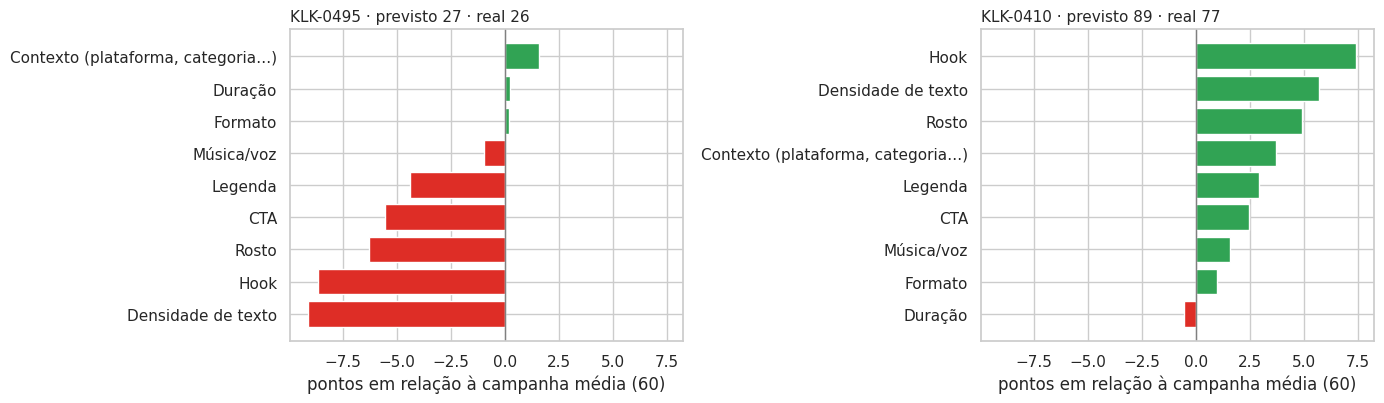

In [11]:
X_imp = pd.DataFrame(model_A[0].transform(XA), columns=XA.columns, index=XA.index)
contrib = (X_imp - X_imp.mean()) * coef
base_value = model_A.predict(XA).mean()

family = {}
for c in XA.columns:
    if c.startswith(("hook", "face", "cta", "subtitle")) or "×hook" in c or "×face" in c or "×subtitle" in c:
        key = next(k for k in ["hook", "face", "cta", "subtitle"] if k in c)
        family[c] = {"hook": "Hook", "face": "Rosto", "cta": "CTA", "subtitle": "Legenda"}[key]
    elif "text_density" in c: family[c] = "Densidade de texto"
    elif "format" in c: family[c] = "Formato"
    elif c == "music_voice_ratio": family[c] = "Música/voz"
    elif c == "log_duration": family[c] = "Duração"
    else: family[c] = "Contexto (plataforma, categoria…)"
by_family = contrib.T.groupby(family).sum().T

meta = df["platform"] == "Meta"
pred = pd.Series(model_A.predict(XA), index=df.index)
examples = [pred[meta].idxmin(), pred[meta].idxmax()]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
for ax, i in zip(axes, examples):
    s = by_family.loc[i].sort_values()
    ax.barh(s.index, s.values, color=["#de2d26" if v < 0 else "#31a354" for v in s.values])
    ax.axvline(0, color="gray", lw=1)
    r = df.loc[i]
    ax.set_title(f"{r['campaign_id']} · previsto {pred[i]:.0f} · real {r[TARGET]:.0f}", loc="left", fontsize=11)
    ax.set_xlabel(f"pontos em relação à campanha média ({base_value:.0f})")
plt.tight_layout()
fig.savefig(FIGURES_MODEL / "05_explicacao_previsao.png", dpi=150, bbox_inches="tight")
df.loc[examples, ["campaign_id", "platform", "has_hook", "has_face", "has_cta", "has_subtitle", "text_density", "format", TARGET]]

**📊 Como ler:** cada barra mostra quantos pontos aquele aspecto da campanha soma (verde) ou tira (vermelho) em relação a uma campanha média. A soma das barras mais o score médio dá o score previsto.

**💡 Takeaway:** é assim que a engine vai **explicar** cada recomendação. A campanha da esquerda perde pontos por não ter hook, rosto e boas práticas de texto; essas barras vermelhas são exatamente as oportunidades de melhoria que a Parte 3 transforma em sugestões priorizadas.

## 8. Resumo

| Pergunta | Resposta |
|---|---|
| **Features** | Atributos do criativo + contexto, com **interações por plataforma** (novas) e flag de legenda faltante. Métricas de performance ficam **fora** do modelo principal para evitar vazamento: elas não existem antes da veiculação. |
| **Modelo** | **Regressão linear (Ridge)**. Ganhou do gradient boosting na validação cruzada, é interpretável e é estável com 500 linhas. |
| **Avaliação** | R² ≈ 0,71 e erro médio ≈ 6,6 pts (contra 12,6 do baseline), sem viés entre plataformas. Bom para comparar criativos e estimar efeitos de mudanças; impreciso para cravar o score de uma campanha (erro > 10 pts em 1 a cada 4). |
| **Importância** | Hook ≫ rosto > texto > legenda ≈ CTA; o contexto pesa pouco. Faz sentido: o score mede o criativo. |
| **Engenharia reversa** | Hook ≈ +16–19 pts, rosto ≈ +11, CTA ≈ +8, legenda ≈ +4–10, texto high ≈ −7, formato depende da plataforma. O score parece ser "checklist de boas práticas + performance + ruído". |

**Limitações**
- 500 campanhas simuladas; o LinkedIn tem 83.
- Os coeficientes são **associações ajustadas**, não efeitos causais garantidos (ver EDA, seção 2.2).
- O modelo supõe que os efeitos se somam. Os dados sustentam isso (o linear ganhou do boosting), mas em dados reais pode haver interações que 500 linhas não revelam.